In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [6]:
df = pd.read_csv("customers.csv", sep="\t")

df.head(3)

,signup_date,last_purchase_date,total_spend,visits,churned
0,2024-03-25,2024-05-16,3196.62,17,1
1,2023-04-27,2024-05-06,756.30,12,1
2,2022-02-26,2023-06-18,4579.50,17,1


In [7]:
df['signup_date'] = pd.to_datetime(df['signup_date'])
df['last_purchase_date'] = pd.to_datetime(df['last_purchase_date'])
print(df)

    signup_date last_purchase_date  total_spend  visits  churned
0    2024-03-25         2024-05-16      3196.62      17        1
1    2023-04-27         2024-05-06       756.30      12        1
2    2022-02-26         2023-06-18      4579.50      17        1
3    2023-10-09         2024-09-28      5842.66      12        1
4    2024-03-21         2024-05-25     10934.32      21        0
..          ...                ...          ...     ...      ...
195  2022-01-26         2023-06-16     26842.74      18        1
196  2023-04-02         2023-06-12     12275.10      10        1
197  2022-08-15         2024-02-14      1697.63      18        1
198  2022-12-09         2023-02-16       381.55      18        1
199  2022-02-23         2023-04-17     15133.21      16        1

[200 rows x 5 columns]


In [8]:
print(df.shape)

(200, 5)


In [9]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   signup_date         200 non-null    datetime64[us]
 1   last_purchase_date  200 non-null    datetime64[us]
 2   total_spend         200 non-null    float64       
 3   visits              200 non-null    int64         
 4   churned             200 non-null    int64         
dtypes: datetime64[us](2), float64(1), int64(2)
memory usage: 7.9 KB
None


In [10]:
print(df.isnull().sum())

signup_date           0
last_purchase_date    0
total_spend           0
visits                0
churned               0
dtype: int64


In [12]:
df["signup_date"] = pd.to_datetime(df["signup_date"])
df["last_purchase_date"] = pd.to_datetime(df["last_purchase_date"])

display(df.head(5))

,signup_date,last_purchase_date,total_spend,visits,churned
0,2024-03-25,2024-05-16,3196.62,17,1
1,2023-04-27,2024-05-06,756.30,12,1
2,2022-02-26,2023-06-18,4579.50,17,1
3,2023-10-09,2024-09-28,5842.66,12,1
4,2024-03-21,2024-05-25,10934.32,21,0


In [14]:

df["signup_year"] = df["signup_date"].dt.year
df["signup_month"] = df["signup_date"].dt.month

df["signup_weekday"] = df["signup_date"].dt.weekday

reference_date = pd.Timestamp("2025-01-01")

df["days_since_last_purchase"] = (
    reference_date - df["last_purchase_date"]
).dt.days

display(df[[
    "signup_date",
    "signup_year",
    "signup_month",
    "signup_weekday",
    "last_purchase_date",
    "days_since_last_purchase"
]].head(10))

C:\Users\hp\AppData\Local\Temp\ipykernel_1432\2068958215.py:4: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["signup_weekday"] = df["signup_date"].dt.weekday


,signup_date,signup_year,signup_month,signup_weekday,last_purchase_date,days_since_last_purchase
0,2024-03-25,2024,3,0,2024-05-16,230
1,2023-04-27,2023,4,3,2024-05-06,240
2,2022-02-26,2022,2,5,2023-06-18,563
3,2023-10-09,2023,10,0,2024-09-28,95
4,2024-03-21,2024,3,3,2024-05-25,221
5,2024-04-25,2024,4,3,2024-05-18,228
6,2022-08-05,2022,8,4,2023-11-22,406
7,2024-06-15,2024,6,5,2024-08-12,142
8,2022-10-30,2022,10,6,2024-07-15,170
9,2024-03-06,2024,3,2,2024-12-04,28


In [15]:
df["spend_per_visit"] = df["total_spend"] / df["visits"]

display(df[[
    "total_spend",
    "visits",
    "spend_per_visit"
]].head(10))

,total_spend,visits,spend_per_visit
0,3196.62,17,188.036471
1,756.30,12,63.025000
2,4579.50,17,269.382353
3,5842.66,12,486.888333
4,10934.32,21,520.681905
5,10557.19,10,1055.719000
6,570.66,14,40.761429
7,967.40,8,120.925000
8,5530.55,13,425.426923
9,5522.26,13,424.789231


In [16]:
df["log_total_spend"] = np.log1p(df["total_spend"])

display(df[[
    "total_spend",
    "log_total_spend"
]].head(10))

,total_spend,log_total_spend
0,3196.62,8.070162
1,756.30,6.629759
2,4579.50,8.429563
3,5842.66,8.673113
4,10934.32,9.299753
5,10557.19,9.264657
6,570.66,6.348544
7,967.40,6.875645
8,5530.55,8.618223
9,5522.26,8.616724


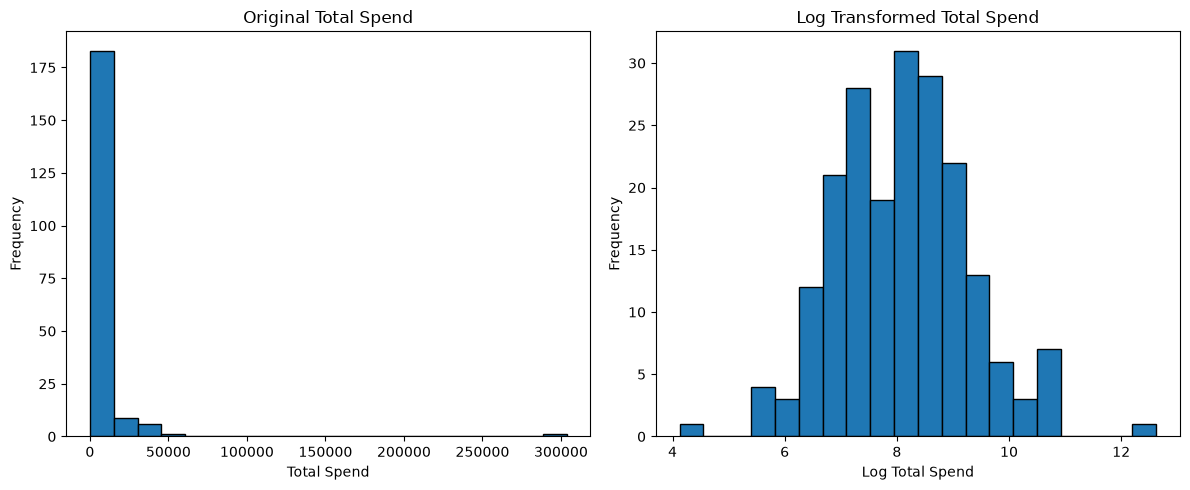

In [17]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(df["total_spend"], bins=20, edgecolor="black")
plt.title("Original Total Spend")
plt.xlabel("Total Spend")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.hist(df["log_total_spend"], bins=20, edgecolor="black")
plt.title("Log Transformed Total Spend")
plt.xlabel("Log Total Spend")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [18]:
new_features = [
    "signup_year",
    "signup_month",
    "signup_weekday",
    "days_since_last_purchase",
    "spend_per_visit",
    "log_total_spend"
]

correlation = df[new_features + ["churned"]].corr()

churn_correlation = correlation["churned"].drop("churned")

correlation_table = churn_correlation.to_frame(
    name="Correlation with Churned"
)

correlation_table["Absolute Correlation"] = (
    correlation_table["Correlation with Churned"].abs()
)

correlation_table = correlation_table.sort_values(
    by="Absolute Correlation",
    ascending=False
)

display(correlation_table)

,Correlation with Churned,Absolute Correlation
days_since_last_purchase,0.578978,0.578978
signup_year,-0.329764,0.329764
signup_month,0.107188,0.107188
log_total_spend,-0.098153,0.098153
spend_per_visit,-0.086832,0.086832
signup_weekday,-0.020520,0.020520


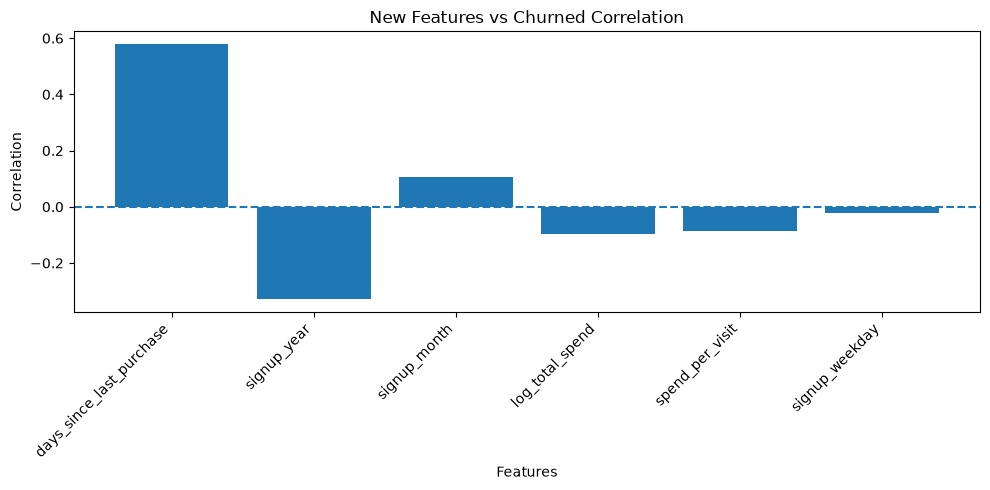

In [19]:
plt.figure(figsize=(10, 5))

plt.bar(
    correlation_table.index,
    correlation_table["Correlation with Churned"]
)

plt.title("New Features vs Churned Correlation")
plt.xlabel("Features")
plt.ylabel("Correlation")

plt.xticks(rotation=45, ha="right")
plt.axhline(y=0, linestyle="--")

plt.tight_layout()
plt.show()

In [21]:
most_useful_feature = correlation_table[
    "Absolute Correlation"
].idxmax()

strongest_correlation = correlation_table.loc[
    most_useful_feature,
    "Correlation with Churned"
]


print("Feature:", most_useful_feature)
print("Correlation:", round(strongest_correlation, 4))

if strongest_correlation > 0:
    print("Relationship: Positive correlation with churn.")
else:
    print("Relationship: Negative correlation with churn.")

Feature: days_since_last_purchase
Correlation: 0.579
Relationship: Positive correlation with churn.


In [23]:

display(df.head(10))


,signup_date,last_purchase_date,total_spend,visits,churned,signup_year,signup_month,signup_weekday,days_since_last_purchase,spend_per_visit,log_total_spend
0,2024-03-25,2024-05-16,3196.62,17,1,2024,3,0,230,188.036471,8.070162
1,2023-04-27,2024-05-06,756.30,12,1,2023,4,3,240,63.025000,6.629759
2,2022-02-26,2023-06-18,4579.50,17,1,2022,2,5,563,269.382353,8.429563
3,2023-10-09,2024-09-28,5842.66,12,1,2023,10,0,95,486.888333,8.673113
4,2024-03-21,2024-05-25,10934.32,21,0,2024,3,3,221,520.681905,9.299753
5,2024-04-25,2024-05-18,10557.19,10,1,2024,4,3,228,1055.719000,9.264657
6,2022-08-05,2023-11-22,570.66,14,1,2022,8,4,406,40.761429,6.348544
7,2024-06-15,2024-08-12,967.40,8,1,2024,6,5,142,120.925000,6.875645
8,2022-10-30,2024-07-15,5530.55,13,1,2022,10,6,170,425.426923,8.618223
9,2024-03-06,2024-12-04,5522.26,13,0,2024,3,2,28,424.789231,8.616724


In [24]:
print(df.shape)

(200, 11)


In [25]:
print(df.columns.tolist())

['signup_date', 'last_purchase_date', 'total_spend', 'visits', 'churned', 'signup_year', 'signup_month', 'signup_weekday', 'days_since_last_purchase', 'spend_per_visit', 'log_total_spend']


In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   signup_date               200 non-null    datetime64[us]
 1   last_purchase_date        200 non-null    datetime64[us]
 2   total_spend               200 non-null    float64       
 3   visits                    200 non-null    int64         
 4   churned                   200 non-null    int64         
 5   signup_year               200 non-null    int32         
 6   signup_month              200 non-null    int32         
 7   signup_weekday            200 non-null    int32         
 8   days_since_last_purchase  200 non-null    int64         
 9   spend_per_visit           200 non-null    float64       
 10  log_total_spend           200 non-null    float64       
dtypes: datetime64[us](2), float64(3), int32(3), int64(3)
memory usage: 15.0 KB


In [27]:
df.to_csv("customers_with_new_features.csv", index=False)
